# QUESTION 2: Clustering

This notebook explores how different physical characteristics can be used to group houses into categories such as {smaller, older homes}, {mid-size, family homes}, and {larger, higher-quality homes}. These categories would help real estate agents identify comparable homes and investigate potential investment or renovation opportunities. 

# Load Data

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.metrics import adjusted_rand_score

In [3]:
train_data_df = pd.read_csv("../data/train.csv")
test_data_df = pd.read_csv("../data/test.csv")

In [4]:
train_data_df.columns

Index(['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street',
       'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig',
       'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType',
       'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd',
       'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType',
       'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual',
       'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1',
       'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating',
       'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF',
       'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath',
       'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual',
       'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType',
       'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual',
       'GarageCond', 'PavedDrive

In [5]:
# Select physical characteristics (exclude SalePrice and Neighborhood)
features = [
    "LotArea",
    "OverallQual",
    "OverallCond",
    "YearBuilt",
    "YearRemodAdd",
    "TotalBsmtSF",
    "1stFlrSF",
    "2ndFlrSF",
    "GrLivArea",
    "FullBath",
    "HalfBath",
    "BedroomAbvGr",
    "TotRmsAbvGrd",
    "Fireplaces",
    "GarageCars",
    "GarageArea",
    "WoodDeckSF",
    "OpenPorchSF"
]

X = train_data_df[features].copy()

# Impute missing values
imputer = SimpleImputer(strategy="median")
X_imputed = imputer.fit_transform(X)

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

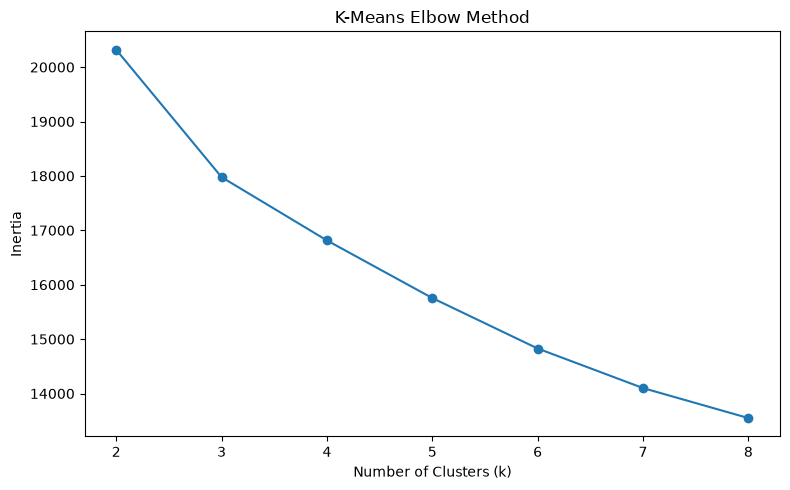

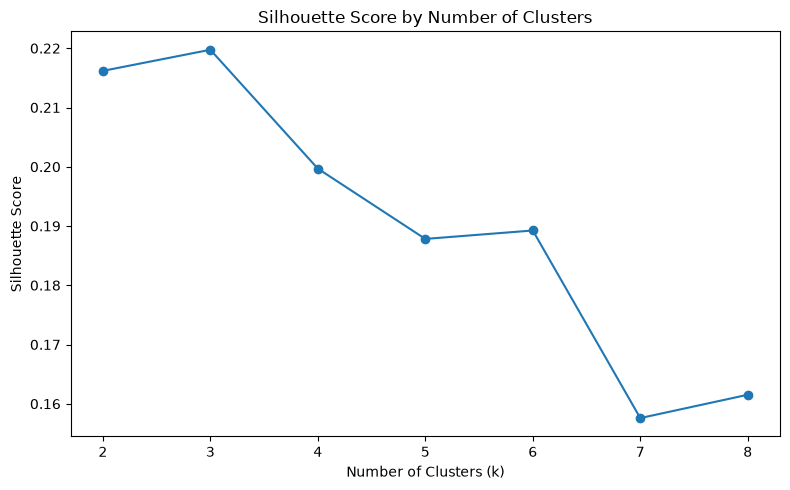

In [6]:
# Compare candidate numbers of clusters
k_values = range(2, 9)
inertias = []
silhouette_scores = []

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)

    inertias.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, labels))

# Elbow method
plt.figure(figsize=(8, 5))
plt.plot(k_values, inertias, marker="o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("K-Means Elbow Method")
plt.xticks(list(k_values))
plt.tight_layout()
plt.show()

# Silhouette scores
plt.figure(figsize=(8, 5))
plt.plot(k_values, silhouette_scores, marker="o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score by Number of Clusters")
plt.xticks(list(k_values))
plt.tight_layout()
plt.show()

In [7]:
# Fit final model (choose k after reviewing both plots)
best_k = 3

kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,TotalBsmtSF,1stFlrSF,2ndFlrSF,GrLivArea,FullBath,HalfBath,BedroomAbvGr,TotRmsAbvGrd,Fireplaces,GarageCars,GarageArea,WoodDeckSF,OpenPorchSF
Cluster,,,,,,,,,,,,,,,,,,
0,11124.78,6.84,5.44,1983.97,1993.71,960.26,1077.15,921.13,2006.75,2.01,0.88,3.39,7.89,0.83,2.14,554.89,117.35,71.77
1,13243.38,7.15,5.16,1993.34,1996.77,1561.15,1616.87,23.52,1640.39,1.90,0.14,2.65,6.64,0.86,2.28,614.90,131.30,64.45
2,8775.62,5.14,5.86,1952.64,1973.66,857.90,981.44,176.73,1165.46,1.14,0.22,2.67,5.65,0.36,1.29,353.04,61.93,22.97


Cluster
0    407
1    355
2    698
Name: count, dtype: int64


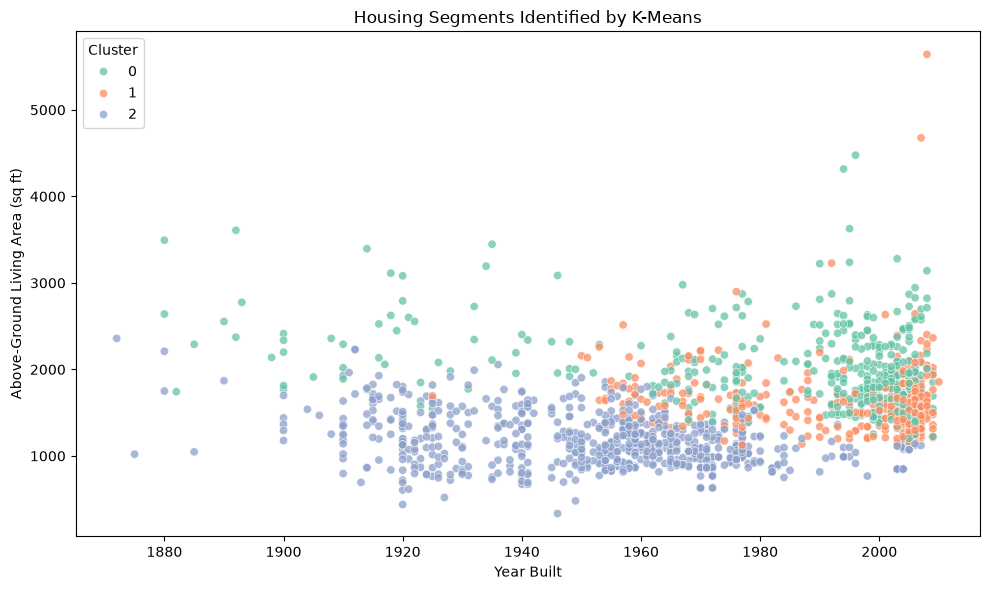

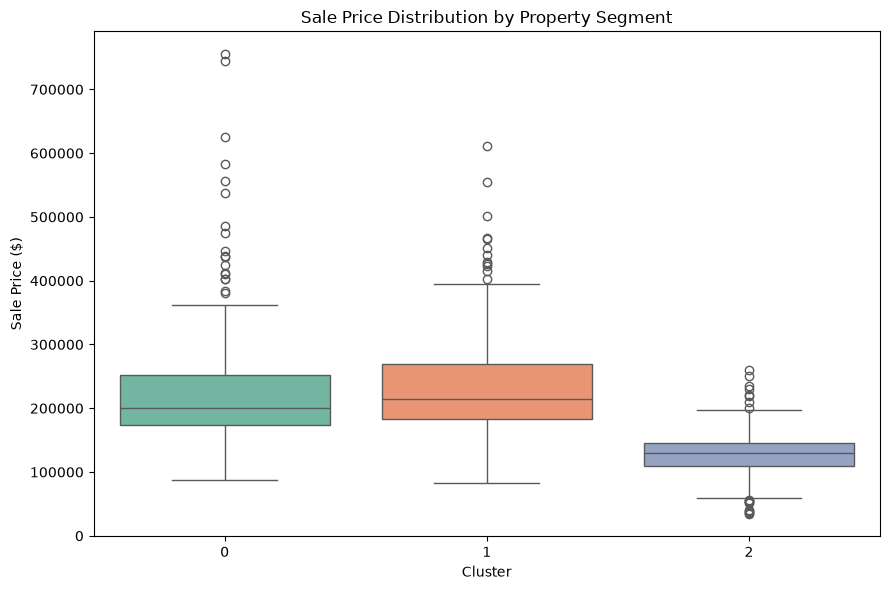

,k,Inertia,Silhouette Score
0,2,20319.100465,0.216182
1,3,17977.409229,0.219746
2,4,16814.221359,0.199687
3,5,15755.082880,0.187821
4,6,14827.590504,0.189242
5,7,14100.546574,0.157585
6,8,13548.859442,0.161519


In [8]:
df_clustered = train_data_df.copy()
df_clustered["Cluster"] = kmeans.fit_predict(X_scaled)

# Summarize the physical characteristics of each cluster
cluster_profiles = df_clustered.groupby("Cluster")[features].mean().round(2)
display(cluster_profiles)

# Compare cluster sizes
print(df_clustered["Cluster"].value_counts().sort_index())

# Visualize clusters by living area and year built
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_clustered,
    x="YearBuilt",
    y="GrLivArea",
    hue="Cluster",
    palette="Set2",
    alpha=0.75
)
plt.title("Housing Segments Identified by K-Means")
plt.xlabel("Year Built")
plt.ylabel("Above-Ground Living Area (sq ft)")
plt.tight_layout()
plt.show()

# Compare sale prices AFTER clustering (not used to create clusters)
plt.figure(figsize=(9, 6))
sns.boxplot(
    data=df_clustered,
    x="Cluster",
    y="SalePrice",
    hue="Cluster",
    palette="Set2",
    legend=False
)
plt.title("Sale Price Distribution by Property Segment")
plt.xlabel("Cluster")
plt.ylabel("Sale Price ($)")
plt.tight_layout()
plt.show()

# Compare silhouette scores numerically
silhouette_results = pd.DataFrame({
    "k": list(k_values),
    "Inertia": inertias,
    "Silhouette Score": silhouette_scores
})
display(silhouette_results)

| Cluster | Suggested Category Name | Reasoning |
| ------- | ----------------------- | --------- |
| 0       | Spacious, High-Quality Two-Story Homes | Average living area is about 2,007 sq ft, with 2.01 full bathrooms, 3.39 bedrooms, and 7.89 rooms. The average second-floor area (921 sq ft) is substantial, suggesting many homes have two stories. Quality is relatively high at 6.84.|
| 1       | Newer, High-Quality Ranch-Style Homes | Newest homes on average (built around 1993), with the largest basements (1,561 sq ft), high quality (7.15), and large garages. Average second-floor area is only 24 sq ft, suggesting predominantly single-story layouts. |
| 2       | Older, Smaller, Lower-Quality Homes | Oldest homes (built around 1953), lowest quality (5.14), smallest living area (1,165 sq ft), fewer bathrooms, smaller garages, and less outdoor space.

## Trying different features

Some of the features are correlated so I will remove some of them and compare the results.

In [9]:
features2 = [
    "LotArea",
    "OverallQual",
    "OverallCond",
    "YearBuilt",
    "YearRemodAdd",
    "TotalBsmtSF",
    "GrLivArea",
    "FullBath",
    "HalfBath",
    "BedroomAbvGr",
    "TotRmsAbvGrd",
    "Fireplaces",
    "GarageCars",
    "WoodDeckSF",
    "OpenPorchSF"
]

In [10]:
X2 = train_data_df[features2].copy()

# Impute missing values
imputer = SimpleImputer(strategy="median")
X_imputed2 = imputer.fit_transform(X2)

# Standardize features
scaler = StandardScaler()
X_scaled2 = scaler.fit_transform(X_imputed2)

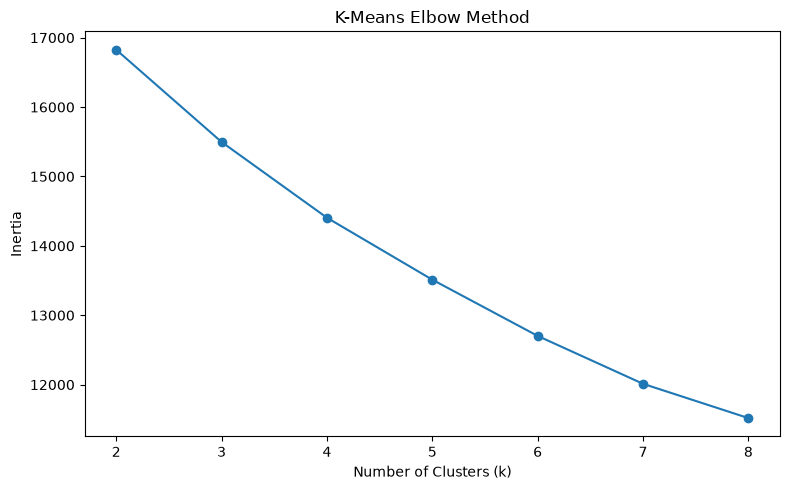

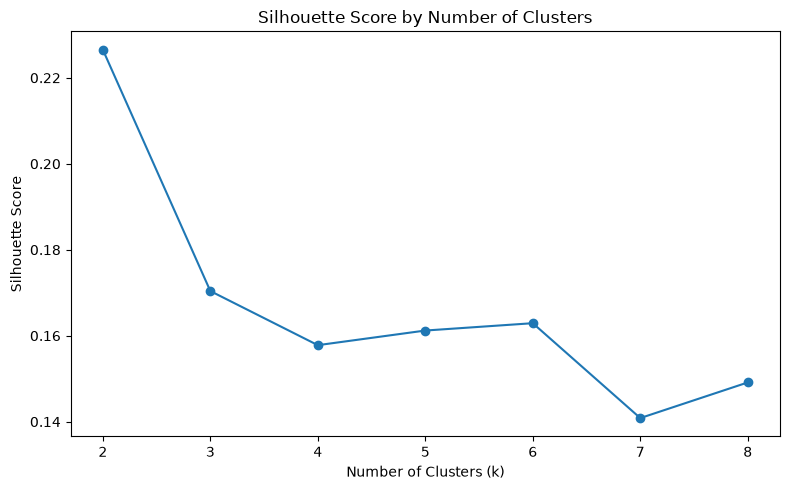

In [11]:
# Compare candidate numbers of clusters
k_values2 = range(2, 9)
inertias2 = []
silhouette_scores2 = []

for k in k_values2:
    kmeans2 = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels2 = kmeans2.fit_predict(X_scaled2)

    inertias2.append(kmeans2.inertia_)
    silhouette_scores2.append(silhouette_score(X_scaled2, labels2))

# Elbow method
plt.figure(figsize=(8, 5))
plt.plot(k_values, inertias2, marker="o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("K-Means Elbow Method")
plt.xticks(list(k_values))
plt.tight_layout()
plt.show()

# Silhouette scores
plt.figure(figsize=(8, 5))
plt.plot(k_values, silhouette_scores2, marker="o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score by Number of Clusters")
plt.xticks(list(k_values))
plt.tight_layout()
plt.show()

In [12]:
# Fit final model (choose k after reviewing both plots)
best_k = 2

kmeans2 = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,TotalBsmtSF,GrLivArea,FullBath,HalfBath,BedroomAbvGr,TotRmsAbvGrd,Fireplaces,GarageCars,WoodDeckSF,OpenPorchSF
Cluster,,,,,,,,,,,,,,,
0,8925.69,5.18,5.87,1952.16,1973.66,863.45,1203.68,1.16,0.23,2.71,5.76,0.38,1.33,63.46,23.92
1,12179.28,7.06,5.27,1991.23,1996.57,1260.11,1841.22,1.99,0.54,3.03,7.31,0.86,2.23,126.40,70.42


Cluster
0    746
1    714
Name: count, dtype: int64


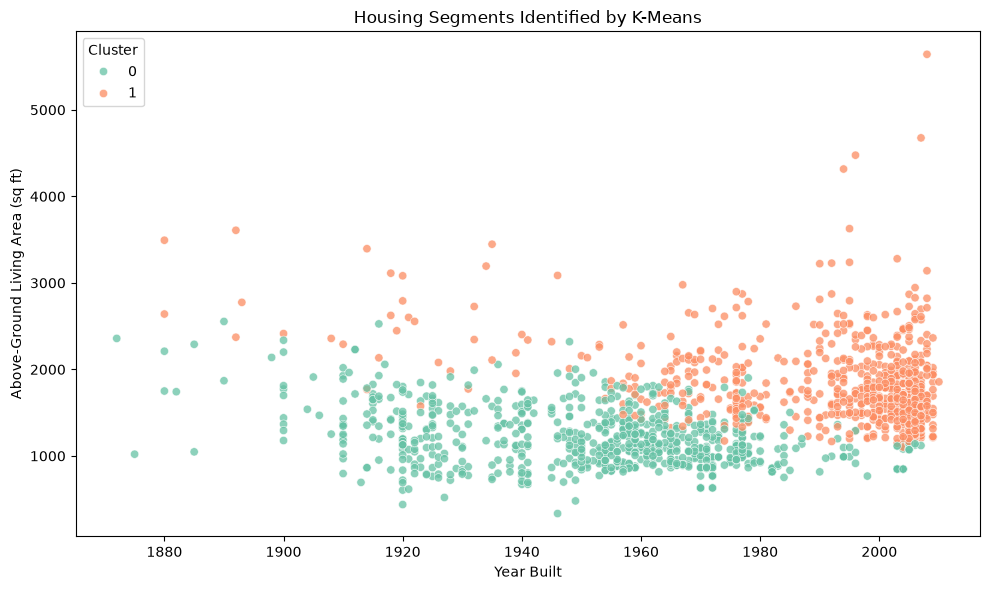

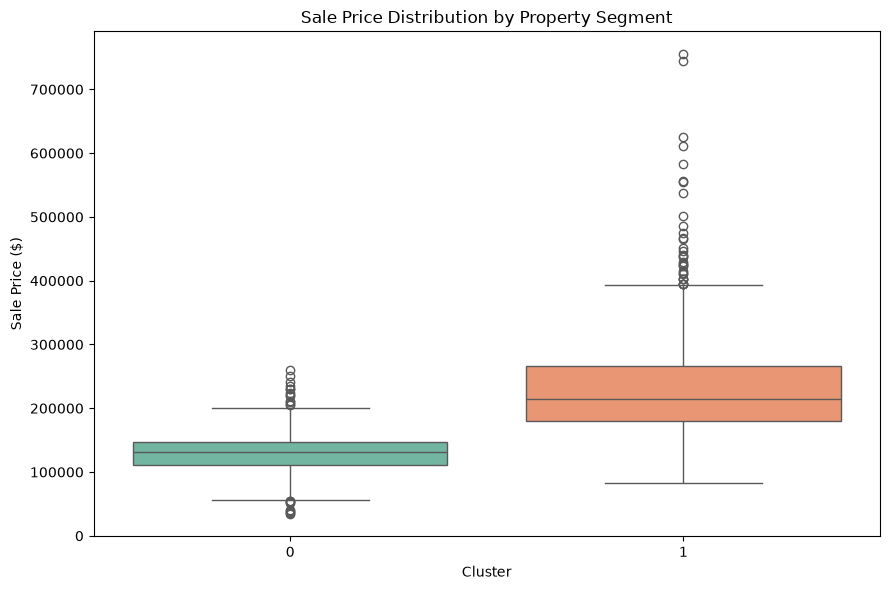

,k,Inertia,Silhouette Score
0,2,20319.100465,0.226531
1,3,17977.409229,0.170388
2,4,16814.221359,0.157799
3,5,15755.082880,0.161202
4,6,14827.590504,0.162911
5,7,14100.546574,0.140836
6,8,13548.859442,0.149127


In [13]:
df_clustered2 = train_data_df.copy()
df_clustered2["Cluster"] = kmeans2.fit_predict(X_scaled2)

# Summarize the physical characteristics of each cluster
cluster_profiles2 = df_clustered2.groupby("Cluster")[features2].mean().round(2)
display(cluster_profiles2)

# Compare cluster sizes
print(df_clustered2["Cluster"].value_counts().sort_index())

# Visualize clusters by living area and year built
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_clustered2,
    x="YearBuilt",
    y="GrLivArea",
    hue="Cluster",
    palette="Set2",
    alpha=0.75
)
plt.title("Housing Segments Identified by K-Means")
plt.xlabel("Year Built")
plt.ylabel("Above-Ground Living Area (sq ft)")
plt.tight_layout()
plt.show()

# Compare sale prices AFTER clustering (not used to create clusters)
plt.figure(figsize=(9, 6))
sns.boxplot(
    data=df_clustered2,
    x="Cluster",
    y="SalePrice",
    hue="Cluster",
    palette="Set2",
    legend=False
)
plt.title("Sale Price Distribution by Property Segment")
plt.xlabel("Cluster")
plt.ylabel("Sale Price ($)")
plt.tight_layout()
plt.show()

# Compare silhouette scores numerically
silhouette_results2 = pd.DataFrame({
    "k": list(k_values),
    "Inertia": inertias,
    "Silhouette Score": silhouette_scores2
})
display(silhouette_results2)

| Cluster | Suggested Category Name | Reasoning |
| ------- | ----------------------- | --------- |
| 0       | Older, Modest Homes | Built around 1952 on average, with the lowest quality rating (5.18), smaller living areas (1,204 sq ft), about 1.16 full bathrooms, and smaller garages.|
| 1       | Newer, Larger, Higher-Quality Homes | Built around 1991 on average, with higher quality (7.06), larger living areas (1,841 sq ft), more bedrooms and rooms, larger basements, and more outdoor amenities. |

## ARI

In [14]:
# We have to make both feature sets have the same number of clusters
km1_k2 = KMeans(n_clusters=2, random_state=42, n_init=10).fit(X_scaled)
km2_k2 = KMeans(n_clusters=2, random_state=42, n_init=10).fit(X_scaled2)
print("ARI, Run 1 vs Run 2 (k=2):", adjusted_rand_score(km1_k2.labels_, km2_k2.labels_))

km1_k3 = KMeans(n_clusters=3, random_state=42, n_init=10).fit(X_scaled)
km2_k3 = KMeans(n_clusters=3, random_state=42, n_init=10).fit(X_scaled2)
print("ARI, Run 1 vs Run 2 (k=3):", adjusted_rand_score(km1_k3.labels_, km2_k3.labels_))

ARI, Run 1 vs Run 2 (k=2): 0.9379364735635911
ARI, Run 1 vs Run 2 (k=3): 0.6215723742645977


# Results

Overall, there are not strongly separated groups of houses in this data. Silhouette scores were low for every k in both runs (about 0.14 to 0.23), so the clusters overlap and should be treated as rough market segments rather than distinct categories.

**Run 1 (18 features, k=3)** gave the best silhouette at k=3 (0.220), narrowly ahead of k=2 (0.216). It split the homes into three segments:
- **Spacious, high-quality two-story homes** (407 homes): about 2,007 sq ft with a large second floor.
- **Newer, high-quality ranch-style homes** (355 homes): built around 1993, with the largest basements and almost no second floor.
- **Older, smaller, lower-quality homes** (698 homes): built around 1953, about 1,165 sq ft.

**Run 2 (15 features after removing correlated ones, k=2)** gave its best silhouette at k=2 (0.227), the highest of any configuration tested, and it dropped sharply at k=3 (0.170). It split the homes into two segments:
- **Older, modest homes:** built around 1952, quality 5.18, about 1,204 sq ft.
- **Newer, larger, higher-quality homes:** built around 1991, quality 7.06, about 1,841 sq ft, with more bedrooms and rooms, larger basements and more outdoor amenities.

To test how sensitive the segments are to feature selection, we computed the Adjusted Rand Index (ARI) between the Run 1 and Run 2 cluster assignments at the same k. At k=2 the ARI was 0.94, meaning the two-cluster split is almost unchanged when correlated features are removed. At k=3 the ARI was 0.62, indicating only moderate agreement and that the three-cluster solution depends more on which features are included. Combined with the higher silhouette score at k=2, this suggests the two-segment split (older, modest homes versus newer, larger, higher-quality homes) is the more stable description of the data, while the three-segment split is useful for categorization but its boundaries are less certain.

Comparing the runs, the two-cluster solution is the more statistically defensible one, since it has the highest silhouette score and a clear break between older, modest homes and newer, larger, higher-quality homes. The three-cluster solution is more useful for the original goal of {smaller older, mid-size family, larger higher-quality} categories, but its extra split (two-story versus ranch) depends heavily on 2ndFlrSF. Removing the correlated features removed that split, and the three-cluster silhouette fell as a result. Both runs agree that age, size and quality drive the grouping and tend to move together, with the older, smaller, lower-quality homes as the most stable segment.

Sale price was not used to build the clusters, but it can be used to check them. The price boxplots can be used to confirm that the segments are ordered by value.

**Practical use:** An agent can use these segments to pick comparable homes (same segment, similar size and age) and to spot renovation opportunities, such as older, modest homes that could be updated toward the newer, higher-quality segment. Because the segments overlap, they should be used alongside other filters such as neighborhood, rather than as hard rules.

**Limitations and next steps:** Silhouette scores are low, K-means assumes roughly spherical clusters, and skewed features such as LotArea may be distorting the distances. Possible improvements are log-transforming skewed variables, trying other methods (Gaussian mixture models, hierarchical clustering), and including categorical features such as house style or neighborhood.